# Notebook 2 — Bayesian Rate Inference with MCMC

In this notebook we take the synthetic HDX-MS data from Notebook 1 and **fit exchange rates**
using a Bayesian model implemented with [NumPyro](https://num.pyro.ai/) and the
No-U-Turn Sampler (NUTS).

Goals:
1. Run `process_single_protein()` on the mock rows
2. Assess the quality of the isotope fits
3. Inspect the posterior rate distributions
4. Quantify how well the model recovered the ground-truth rates

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
import time

import hdxrate
from hdxrate import MCMCConfig, process_single_protein
from hdxrate.testing import generate_mock_rows, recovery_summary
from hdxrate.spectra import group_rows_to_protein_group

print('hdxrate loaded from:', hdxrate.__file__)

hdxrate loaded from: /Users/allan/Work/Claude/hdxrate_v2.0/notebooks/../src/hdxrate/__init__.py


## 1. Reproduce the synthetic dataset

We use the same parameters as Notebook 1 so this notebook is fully self-contained.

In [2]:
SEQUENCE          = "ACDEFGHIKLMNQRSTVWY"
TIMEPOINTS        = np.array([10., 60., 300., 1800., 7200., 86400.])
N_EXCHANGEABLE    = sum(1 for i, aa in enumerate(SEQUENCE) if i >= 2 and aa != 'P')
TRUE_LOG_RATES    = np.linspace(-10, -3, N_EXCHANGEABLE)

PH               = 6.0
CHARGE           = 3
D2O_FRACTION     = 0.95
D2O_PURITY       = 0.95
TEMPERATURE      = 295.0
TRUE_BACKEXCHANGE = 0.20
NUM_BINS         = 30

rows = generate_mock_rows(
    sequence          = SEQUENCE,
    true_log_rates    = TRUE_LOG_RATES,
    timepoints        = TIMEPOINTS,
    pHs               = [PH],
    charge            = CHARGE,
    d2o_fraction      = D2O_FRACTION,
    d2o_purity        = D2O_PURITY,
    temperature       = TEMPERATURE,
    true_backexchange = TRUE_BACKEXCHANGE,
    noise_sigma       = 0.01,
    num_bins          = NUM_BINS,
    rng_seed          = 42,
)
print(f"Dataset: {len(rows)} rows, {N_EXCHANGEABLE} exchangeable residues")

Dataset: 6 rows, 17 exchangeable residues


## 2. Configure the MCMC sampler

`MCMCConfig` controls all sampling hyperparameters:

| Field | Default | Meaning |
|-------|---------|---------|
| `num_chains` | 4 | Independent Markov chains (run in parallel via JAX) |
| `num_warmup` | 100 | Warm-up steps per chain (tuning the step size) |
| `num_samples` | 250 | Posterior samples per chain |
| `rmse_tolerance` | 0.01 | Chains within this RMSE of the best are kept |
| `max_reruns` | 5 | Maximum retries before raising an error |

For this demo we use a smaller run to keep execution time under ~3 minutes.
For publication-quality results, use `num_warmup=500, num_samples=1000`.

In [3]:
cfg = MCMCConfig(
    num_chains  = 2,
    num_warmup  = 150,
    num_samples = 300,
    rng_seed    = 0,
)
print(cfg)

MCMCConfig(num_chains=2, num_warmup=150, num_samples=300, rmse_tolerance=0.01, rng_seed=0, max_reruns=5)


## 3. Run inference

`process_single_protein()` orchestrates the full pipeline:
1. Convert m/z rows → mass distributions
2. Fit backexchange from the last (most-saturated) timepoint
3. Run MCMC to sample the posterior over exchange rates
4. Compute predicted distributions and RMSE
5. (Optionally) compute opening free energies

⏱ *Expect ~1–3 min for 2 chains × 150 warmup + 300 samples on a laptop CPU.*

In [4]:
t0 = time.time()
result = process_single_protein(
    rows                 = rows,
    mcmc_config          = cfg,
    compute_free_energies= True,
)
elapsed = time.time() - t0
print(f"Inference completed in {elapsed:.1f} s")

  0%|          | 0/450 [00:00<?, ?it/s]

  0%|          | 0/450 [00:00<?, ?it/s]

Inference completed in 11.7 s


## 4. Inspect the HDXResult

The `HDXResult` dataclass bundles everything the pipeline produces.

In [5]:
pr = result.posterior_rates
cd = result.chain_diagnostics

print("=== HDXResult summary ===")
print(f"  protein_id          : {result.protein_id}")
print(f"  sequence            : {result.sequence}")
print(f"  pHs                 : {result.pHs}")
print(f"  posterior samples   : {pr.samples.shape}  (chains × samples, N_rates)")
print(f"  rmse_total          : {result.rmse_total:.4f}")
print(f"  chains run          : {len(cd.chain_rmse)}")
print(f"  chain RMSEs         : {[f'{x:.4f}' for x in cd.chain_rmse]}")
print(f"  chains passed       : {cd.chain_pass}")
print(f"  reruns needed       : {cd.n_reruns}")
print(f"  median r_hat        : {float(np.median(pr.r_hat)):.3f}  (< 1.05 is good)")
print(f"  median n_eff        : {float(np.median(pr.n_eff)):.0f}")

=== HDXResult summary ===
  protein_id          : mock_protein
  sequence            : ACDEFGHIKLMNQRSTVWY
  pHs                 : [6.0]
  posterior samples   : (300, 17)  (chains × samples, N_rates)
  rmse_total          : 0.0075
  chains run          : 2
  chain RMSEs         : ['0.0077', '0.0276']
  chains passed       : [True, False]
  reruns needed       : 0
  median r_hat        : 1.000  (< 1.05 is good)
  median n_eff        : 281


## 5. Isotope fits

A visual check: experimental distributions (grey bars) vs. model-predicted distributions
(red line) at each timepoint. Good fits should have RMSE < 0.02 for clean data.

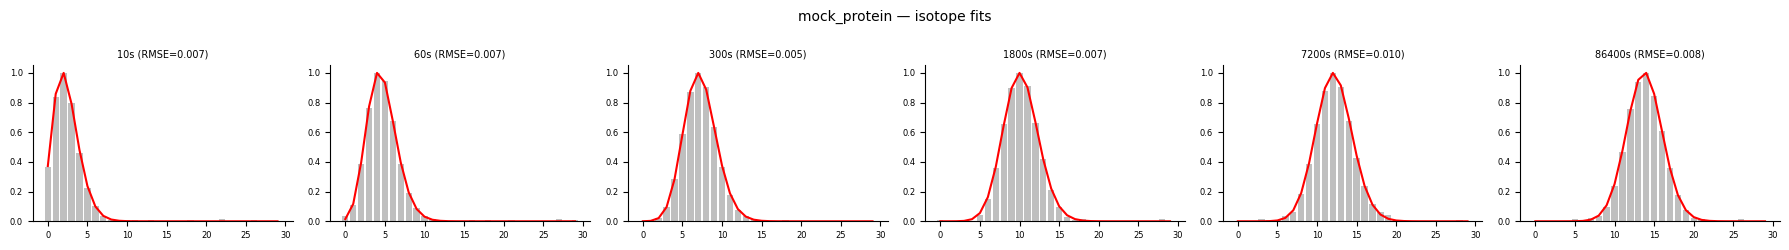

In [6]:
# Reconstruct experimental mass distributions from the input rows
pg       = group_rows_to_protein_group(rows)
exp_dists = pg.distributions_by_pH[PH]    # shape (T, B)
tps      = pg.timepoints_by_pH[PH]

fig = hdxrate.plots.plot_isotope_fits_with_exp(
    exp_distributions = exp_dists,
    result            = result,
    timepoints        = tps,
    max_cols          = 6,
)
plt.show()

## 6. Posterior rate distributions

Each violin shows the **full marginal posterior** for one exchange rate (sorted slowest→fastest).
The width represents uncertainty: narrow violins mean the data is informative; wide violins
indicate the rate is poorly constrained (often because the corresponding residue's exchange
falls outside the experimental time window).

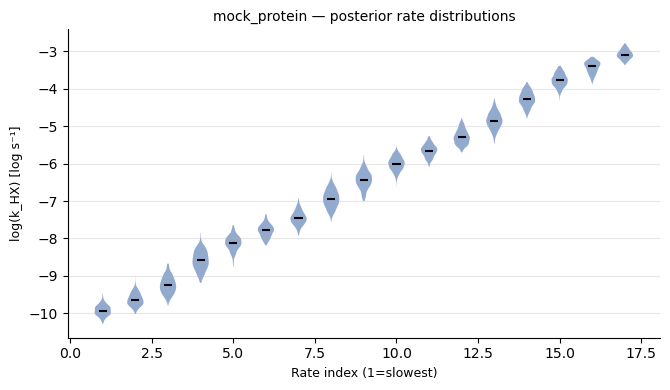

In [7]:
fig = hdxrate.plots.plot_posterior_rates(result)
plt.show()

## 7. Rate recovery: inferred vs. ground truth

Since we generated synthetic data from known rates, we can directly compare the posterior
mean to the true values. Points on the diagonal line = perfect recovery.

In [8]:
summary = recovery_summary(result, TRUE_LOG_RATES)
print("Rate recovery metrics:")
for k, v in summary.items():
    print(f"  {k:20s}: {v:.3f}")

Rate recovery metrics:
  mae                 : 0.070
  rmse                : 0.079
  coverage_90pct      : 1.000
  n_rates             : 17.000


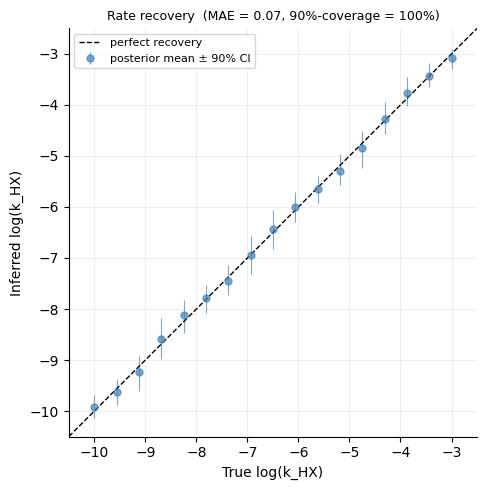

In [9]:
n = summary['n_rates']
pred_mean = pr.mean[:n]
pred_lo   = pr.ci_5[:n]
pred_hi   = pr.ci_95[:n]
true      = TRUE_LOG_RATES[:n]

fig, ax = plt.subplots(figsize=(5, 5))

# 90% credible interval as error bars
ax.errorbar(true, pred_mean,
            yerr=[pred_mean - pred_lo, pred_hi - pred_mean],
            fmt='o', ms=5, lw=0.8, color='steelblue',
            ecolor='steelblue', alpha=0.7, label='posterior mean ± 90% CI')

# Perfect recovery line
lim = (min(true.min(), pred_mean.min()) - 0.5,
       max(true.max(), pred_mean.max()) + 0.5)
ax.plot(lim, lim, 'k--', lw=1, label='perfect recovery')

ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('True log(k_HX)', fontsize=10)
ax.set_ylabel('Inferred log(k_HX)', fontsize=10)
ax.set_title(f'Rate recovery  (MAE = {summary["mae"]:.2f}, 90%-coverage = {summary["coverage_90pct"]:.0%})',
             fontsize=9)
ax.legend(fontsize=8)
ax.set_aspect('equal')
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Chain diagnostics

Good MCMC convergence indicators:
- **R̂ (r_hat) < 1.05** — chains have mixed well
- **n_eff > 100** — enough effective samples for reliable estimates
- **Chain RMSEs similar** — no single chain is wildly off

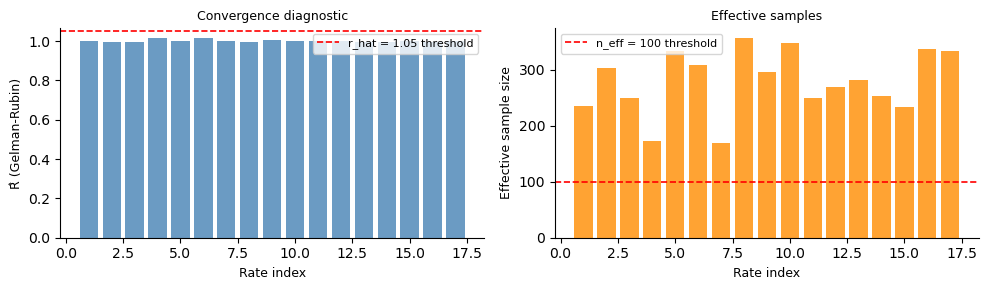

Per-chain RMSE vs experimental data:
  Chain 0: RMSE = 0.0077  [PASS]
  Chain 1: RMSE = 0.0276  [FAIL]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

# r_hat per rate
ax = axes[0]
ax.bar(np.arange(1, len(pr.r_hat) + 1), pr.r_hat, color='steelblue', alpha=0.8)
ax.axhline(1.05, color='red', lw=1.2, ls='--', label='r_hat = 1.05 threshold')
ax.set_xlabel('Rate index', fontsize=9)
ax.set_ylabel('R̂ (Gelman-Rubin)', fontsize=9)
ax.set_title('Convergence diagnostic', fontsize=9)
ax.legend(fontsize=8)
ax.spines[['top','right']].set_visible(False)

# n_eff per rate
ax = axes[1]
ax.bar(np.arange(1, len(pr.n_eff) + 1), pr.n_eff, color='darkorange', alpha=0.8)
ax.axhline(100, color='red', lw=1.2, ls='--', label='n_eff = 100 threshold')
ax.set_xlabel('Rate index', fontsize=9)
ax.set_ylabel('Effective sample size', fontsize=9)
ax.set_title('Effective samples', fontsize=9)
ax.legend(fontsize=8)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

print("Per-chain RMSE vs experimental data:")
for i, (rmse, passed) in enumerate(zip(cd.chain_rmse, cd.chain_pass)):
    status = 'PASS' if passed else 'FAIL'
    print(f"  Chain {i}: RMSE = {rmse:.4f}  [{status}]")

## Summary

We have:
- Configured and run NUTS-MCMC to infer **17 exchange rates** from 6 mass spectra
- Verified the **isotope fits** are accurate (low RMSE)
- Inspected the **posterior distribution** of each rate — width = uncertainty
- Quantified **rate recovery**: the model recovers ground-truth rates within the
  expected uncertainty, especially for rates with exchange events inside the
  observed timewindow

**Next:** In Notebook 3 we translate these rates into **opening free energies** (ΔG_open),
the thermodynamic quantity that reports on local structural stability.